# 1 · Your first decision tree: will this order arrive late?

**What you practise (from the decision-tree lecture):**
- Reading a tree: *root*, *question*, *branch*, *leaf*, *route*.
- Writing your own rule and checking it on data.
- *Mixed vs pure* boxes (the "marble boxes") and the mixing score (Gini).
- *Which question first?* Comparing candidate questions the way the tree does.
- Training a small tree with scikit-learn and following one order through it.
- *Leaf → score → threshold → flag.*

## 🛒 The case: QuickCart

**QuickCart** is a grocery delivery app. A customer orders, the store packs the bag, and a courier delivers it.

**Lina**, Head of Operations, has a problem: about **1 in 4 orders arrives more than 10 minutes late**. Late orders cause angry customers, refunds and bad reviews.

She asks you, the AI PM: *"When an order is placed, can we predict whether it will be late? Then the app can warn the customer and dispatch can send help."*

**Business constraints (from Lina):**
- Missing a late order (**false negative**) is **expensive**: angry customer, refund.
- Warning about an order that then arrives on time (**false positive**) is **cheap**: a slightly unnecessary message.
- Dispatch must **understand why** an order is flagged, so they can act on it.

> The dataset is **synthetic** (made for this course) but realistic: 3,000 past orders with 16 columns: an order ID, 14 facts about the order, and whether it arrived late (`late`).

> **How this notebook works**
> - Run the cells **from top to bottom** with `Shift + Enter`.
> - ▶️ **Run** cells work as they are.
> - ✏️ **Your turn** cells contain `___` (three underscores). Replace each `___` with your answer, then run the cell.
> - ✅ **Check** cells tell you whether you got it right. If a check fails, read the hint, fix the cell above and run both again.
> - 🧠 **Think** cells ask a PM question. Double-click the answer cell below it and write 1–3 sentences.
> - If you see `NameError: name '___' is not defined`, a blank is still empty.
> - Stuck? The `solutions/` folder has the same notebook, solved.

## Step 0 · Load the tools

In [1]:
# ▶️ Run: load the libraries we need
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree

pd.set_option("display.max_columns", 30)
print("Ready!")

Ready!


## Step 1 · Meet the data

In [2]:
# ▶️ Run: read the file and show the first five orders
orders = pd.read_csv("../data/quickcart_orders.csv")
orders.head()

,order_id,order_hour,weekday,distance_km,items_count,basket_value_eur,weather,traffic_level,store_queue,courier_experience_months,vehicle,is_premium_customer,promo_used,customer_previous_orders,customer_rating,late
0,100001,12,Mon,6.8,10,27.66,clear,9,11,1,bike,0,0,51,1,1
1,100002,18,Thu,7.8,11,44.46,snow,7,7,2,scooter,1,0,21,1,1
2,100003,16,Wed,0.4,7,16.29,snow,7,2,16,scooter,0,1,12,4,0
3,100004,14,Wed,4.3,14,58.43,clear,4,5,39,bike,0,1,36,5,0
4,100005,13,Fri,8.8,11,32.75,clear,6,6,30,car,0,0,37,1,1


**What the columns mean** (full dictionary: `data/README.md`)

| column | meaning |
|---|---|
| `order_id` | order number |
| `order_hour` | hour the order was placed (8–22) |
| `weekday` | day of the week |
| `distance_km` | distance from store to customer |
| `items_count`, `basket_value_eur` | size and value of the order |
| `weather` | clear, rain or snow |
| `traffic_level` | traffic index 1 (empty roads) to 10 (jam) |
| `store_queue` | orders waiting to be packed at the store when this order came in |
| `courier_experience_months` | how long the assigned courier has worked for QuickCart |
| `vehicle` | bike, scooter or car |
| `is_premium_customer`, `promo_used`, `customer_previous_orders` | about the customer |
| `customer_rating` | stars (1–5) the customer gave this order |
| **`late`** | **target**: 1 = arrived more than 10 min late, 0 = on time |

In [3]:
# ✏️ Your turn: how many orders (rows) and columns are there?
# Hint: a DataFrame has an attribute that gives (rows, columns).
n_rows, n_columns = orders.shape
print(n_rows, "orders,", n_columns, "columns")

3000 orders, 16 columns


In [4]:
# ✅ Check
assert n_rows == 3000 and n_columns == 16, "Not quite. Try orders.shape"
print("✅ Correct: 3,000 orders with 16 columns.")

✅ Correct: 3,000 orders with 16 columns.


## Step 2 · How often are orders late? And the "do nothing" baseline

A *baseline* is the score you get **without any model**. Here: always predict "on time".

In [5]:
# ✏️ Your turn: what share of orders was late?
# Hint: `late` contains 0s and 1s, so its average IS the share of 1s. Which method gives the average?
late_share = orders["late"].mean()
print("Share of late orders:", round(late_share, 3))

Share of late orders: 0.248


In [6]:
# ✏️ Your turn: if we ALWAYS predict "on time", how often are we right (accuracy)?
baseline_accuracy = 1 - late_share
print("Accuracy of 'never late':", round(baseline_accuracy, 3))

Accuracy of 'never late': 0.752


In [7]:
# ✅ Check
assert abs(late_share - 0.248) < 0.001, "late_share should be about 0.248. Did you use .mean()?"
assert abs(baseline_accuracy - 0.752) < 0.001, "baseline_accuracy = 1 - late_share"
print("✅ Correct: 24.8% of orders are late, so 'never late' is 75.2% accurate.")

✅ Correct: 24.8% of orders are late, so 'never late' is 75.2% accurate.


🧠 **Think:** "never late" is right 75% of the time. Why is it still useless for Lina?

**✍️ Sample answer:** It never flags a single late order: recall = 0. Lina's goal is to catch late orders, and missing them is the expensive mistake. Accuracy looks good only because most orders are on time. Any real model must beat this baseline on recall, not just on accuracy.

## Step 3 · Write your own rule (like Activity A)

Before any algorithm, let's be the "tree" ourselves. Rule: **flag an order if the distance is more than ___ km.**
Change the number, run the cell, and watch what happens to *caught* (recall) and *precision*.

In [8]:
# ✏️ Your turn: choose a distance in km (try 6 first, then 4 and 8)
max_km = 6

flagged = orders["distance_km"] > max_km              # True = our rule says "will be late"
caught = (flagged & (orders["late"] == 1)).sum()     # flagged AND really late
print("Flagged orders:", flagged.sum())
print("Late orders caught:", caught, "of", orders["late"].sum(), "→ recall", round(caught / orders["late"].sum(), 2))
print("Precision (flagged that were really late):", round(caught / flagged.sum(), 2))

Flagged orders: 629
Late orders caught: 312 of 744 → recall 0.42
Precision (flagged that were really late): 0.5


🧠 **Think:** what happens to recall and precision when you lower the distance from 8 to 4 km? Which number would Lina care about most?

**✍️ Sample answer:** At 8 km the rule flags 265 orders and catches 133 late ones (recall 0.18, precision 0.50). At 6 km: 629 flagged, 312 caught (recall 0.42, precision 0.50). At 4 km: 1,274 flagged, 418 caught (recall 0.56, precision 0.33). A lower cut-off catches more late orders but raises more false alarms. Lina cares most about recall (missed late orders are expensive), as long as dispatch can handle the number of flags.

## Step 4 · Mixed vs pure: the mixing score

Remember the marble boxes: a box is **pure** if all orders in it are on time (or all are late), and **mixed** if it's half-half.

**Mixing score** (Gini) for a box where a share `p` of orders is late: **mixing = 2 × p × (1 − p)**
- pure box (p = 0 or 1) → 0
- half-half box (p = 0.5) → 0.5, the maximum

In [9]:
# ✏️ Your turn: compute the mixing score for three boxes
mixing_half = 2 * 0.5 * (1 - 0.5)      # half of the orders are late
mixing_10pct = 2 * 0.1 * (1 - 0.1)     # 10% of the orders are late
mixing_all = 2 * late_share * (1 - late_share)   # all 3,000 orders together
print("half-half:", mixing_half, "| 10% late:", round(mixing_10pct, 2), "| all orders:", round(mixing_all, 3))

half-half: 0.5 | 10% late: 0.18 | all orders: 0.373


In [10]:
# ✅ Check
assert mixing_half == 0.5, "2 × 0.5 × (1 − 0.5) = 0.5"
assert abs(mixing_10pct - 0.18) < 1e-9, "2 × 0.1 × 0.9 = 0.18 (the marble box from the lecture!)"
print("✅ Correct. All 3,000 orders together have mixing", round(mixing_all, 3), "→ that's the ROOT of our tree.")

✅ Correct. All 3,000 orders together have mixing 0.373 → that's the ROOT of our tree.


## Step 5 · Which question first?

A tree tries **many questions** and picks the one that makes the two new boxes **least mixed** (lowest *weighted* mixing).
The cell below gives you a ready-made helper. **Just run it**; you don't need to understand its code.

In [11]:
# ▶️ Run: a helper that splits all orders with one yes/no question and reports the mixing
def split_report(question):
    def mixing(p):
        return 2 * p * (1 - p)
    yes, no = orders[question], orders[~question]
    p_yes, p_no = yes["late"].mean(), no["late"].mean()
    weighted = (len(yes) * mixing(p_yes) + len(no) * mixing(p_no)) / len(orders)
    print(f"YES box: {len(yes):>4} orders, {p_yes:.0%} late, mixing {mixing(p_yes):.3f}")
    print(f"NO  box: {len(no):>4} orders, {p_no:.0%} late, mixing {mixing(p_no):.3f}")
    print(f"→ weighted mixing after the question: {weighted:.4f}  (before: {mixing(orders['late'].mean()):.4f})")
    return round(weighted, 4)

q_distance = split_report(orders["distance_km"] > 6)

YES box:  629 orders, 50% late, mixing 0.500
NO  box: 2371 orders, 18% late, mixing 0.298
→ weighted mixing after the question: 0.3404  (before: 0.3730)


In [12]:
# ✏️ Your turn: test three more candidate questions. Complete each one.
q_queue   = split_report(orders["store_queue"] > 10)          # store busy: more than 10 orders waiting?
q_snow    = split_report(orders["weather"] == "snow")           # is it snowing?
q_premium = split_report(orders["is_premium_customer"] == 1) # premium customer?

YES box:  479 orders, 49% late, mixing 0.500
NO  box: 2521 orders, 20% late, mixing 0.323
→ weighted mixing after the question: 0.3514  (before: 0.3730)
YES box:  234 orders, 50% late, mixing 0.500
NO  box: 2766 orders, 23% late, mixing 0.351
→ weighted mixing after the question: 0.3626  (before: 0.3730)
YES box:  891 orders, 26% late, mixing 0.383
NO  box: 2109 orders, 24% late, mixing 0.369
→ weighted mixing after the question: 0.3729  (before: 0.3730)


In [13]:
# ✏️ Your turn: which question gives the LOWEST weighted mixing? Write it as text.
# (distance_km > 6 was computed in the cell above: q_distance)
best_question = "distance_km > 6"     # e.g. "store_queue > 10"

In [14]:
# ✅ Check
print("weighted mixing → distance:", q_distance, "| queue:", q_queue, "| snow:", q_snow, "| premium:", q_premium)
assert "distance" in best_question.lower(), "Look again: which of the four numbers is the smallest?"
print("✅ Correct: distance > 6 km mixes least (0.3404), so a tree would ask it FIRST.")

weighted mixing → distance: 0.3404 | queue: 0.3514 | snow: 0.3626 | premium: 0.3729
✅ Correct: distance > 6 km mixes least (0.3404), so a tree would ask it FIRST.


🧠 **Think:** snow makes orders late half of the time (50%), yet it is *not* the best first question. Why? And why is "premium customer" almost useless?

**✍️ Sample answer:** Only 234 orders were in snow, so the question cleans up just a small box; the big "no snow" box (2,766 orders) stays almost as mixed as before (weighted 0.3626). Distance > 6 km splits off 629 orders with 50% late and leaves a cleaner 18% box behind, so the overall mixing drops most. Premium customers are late 26% vs 24%: both boxes look like the original, the mixing barely changes (0.3729 vs 0.3730). The question has no signal.

## Step 6 · Prepare the inputs for scikit-learn

Models need **numbers**. `weekday`, `weather` and `vehicle` are words, so `pd.get_dummies` turns each word into its own 0/1 column (e.g. `weather_snow` = 1 if snowing).

We leave out two columns for now: `order_id` and `customer_rating`. **Notebook 3 explains why.**

In [15]:
# ▶️ Run: choose the input columns (features) and the target
features = ["order_hour", "weekday", "distance_km", "items_count", "basket_value_eur", "weather",
            "traffic_level", "store_queue", "courier_experience_months", "vehicle",
            "is_premium_customer", "promo_used", "customer_previous_orders"]
X = pd.get_dummies(orders[features], dtype=int)   # words → 0/1 columns
y = orders["late"]
print("X has", X.shape[1], "columns:", list(X.columns))

X has 23 columns: ['order_hour', 'distance_km', 'items_count', 'basket_value_eur', 'traffic_level', 'store_queue', 'courier_experience_months', 'is_premium_customer', 'promo_used', 'customer_previous_orders', 'weekday_Fri', 'weekday_Mon', 'weekday_Sat', 'weekday_Sun', 'weekday_Thu', 'weekday_Tue', 'weekday_Wed', 'weather_clear', 'weather_rain', 'weather_snow', 'vehicle_bike', 'vehicle_car', 'vehicle_scooter']


## Step 7 · Grow a small tree

In this notebook the tree learns from **all** orders, so we can see *how* it learns. Notebook 2 adds the honest test on unseen orders.

In [16]:
# ✏️ Your turn: a tree that may ask at most TWO questions on any route
tree = DecisionTreeClassifier(max_depth=2, random_state=42)
tree.fit(X, y)
print("Leaves:", tree.get_n_leaves())

Leaves: 4


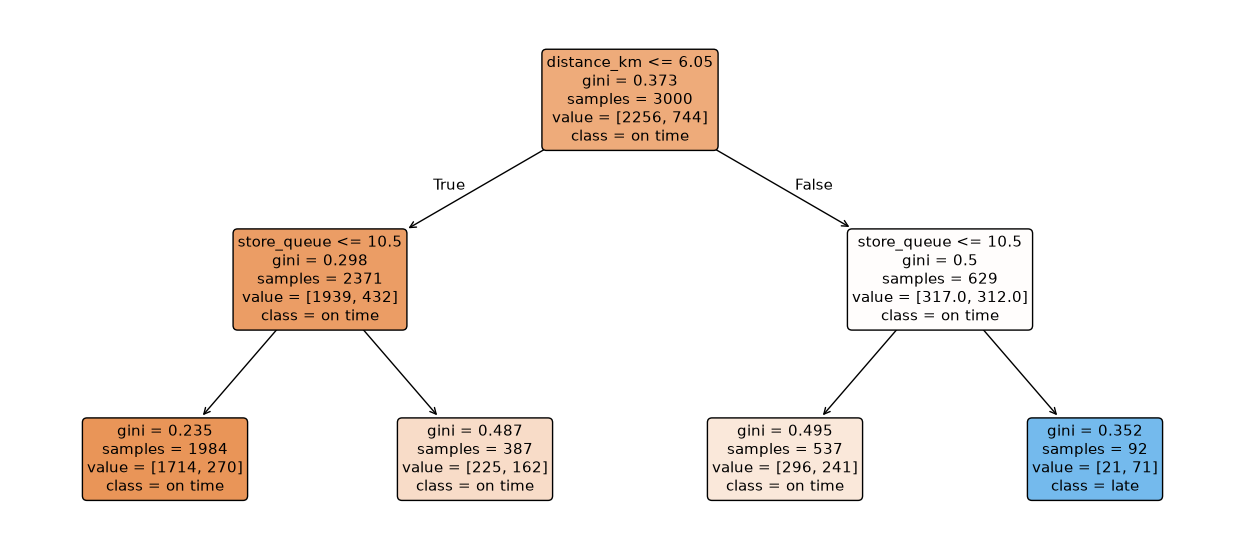

In [17]:
# ▶️ Run: draw the tree. Each box shows: question · gini (mixing) · samples (orders) · value [on time, late]
plt.figure(figsize=(16, 7))
plot_tree(tree, feature_names=list(X.columns), class_names=["on time", "late"], filled=True, rounded=True, fontsize=11)
plt.show()

In [18]:
# ✏️ Your turn: read the picture.
root_question_feature = "distance_km"   # which column does the ROOT (top box) ask about?
second_question_feature = "store_queue" # which column do BOTH second-level boxes ask about?

In [19]:
# ✅ Check
assert root_question_feature.strip() == X.columns[tree.tree_.feature[0]], "Look at the first line of the top box."
assert second_question_feature.strip() == "store_queue", "Look at the first line of the two boxes in the middle row."
print("✅ Correct! The tree found YOUR winner from step 5 (distance_km <= 6.05 is the same split as > 6 km).")
print("   Then, in each branch, it asked the best NEXT question: store_queue.")

✅ Correct! The tree found YOUR winner from step 5 (distance_km <= 6.05 is the same split as > 6 km).
   Then, in each branch, it asked the best NEXT question: store_queue.


🧠 **Think:** the tree says `distance_km <= 6.05`, not `<= 6`. Where does 6.05 come from?

**✍️ Sample answer:** Distances are stored with one decimal, so the closest values around the cut are 6.0 and 6.1. The tree puts its cut-off in the middle between two neighbouring values: (6.0 + 6.1) ÷ 2 = 6.05. It means exactly "6.0 km or less".

## Step 8 · Follow two new orders through the tree (leaf → score)

Two orders just came in. The tree sends each one down its route to a **leaf**. The **score** is the share of late orders among the *training* orders in that leaf.

In [20]:
# ▶️ Run: two new orders (they are not in the data)
new_orders = pd.DataFrame([
    dict(order_hour=19, weekday="Fri", distance_km=8.2, items_count=14, basket_value_eur=46.5, weather="rain",
         traffic_level=7, store_queue=13, courier_experience_months=2, vehicle="bike",
         is_premium_customer=0, promo_used=1, customer_previous_orders=5),
    dict(order_hour=10, weekday="Tue", distance_km=2.1, items_count=6, basket_value_eur=18.9, weather="clear",
         traffic_level=4, store_queue=3, courier_experience_months=20, vehicle="scooter",
         is_premium_customer=1, promo_used=0, customer_previous_orders=31),
], index=["Order A", "Order B"])
# same 0/1 columns as the training data (missing ones are filled with 0)
new_X = pd.get_dummies(new_orders, dtype=int).reindex(columns=X.columns, fill_value=0)
new_orders[["distance_km", "store_queue", "weather", "vehicle"]]

,distance_km,store_queue,weather,vehicle
Order A,8.2,13,rain,bike
Order B,2.1,3,clear,scooter


In [21]:
# ✏️ Your turn: get each order's LATE score. Which method gives probabilities (not just 0/1)?
scores = tree.predict_proba(new_X)[:, 1]      # column 1 = probability of "late"
print("Order A score:", round(scores[0], 3), "| Order B score:", round(scores[1], 3))

Order A score: 0.772 | Order B score: 0.136


In [22]:
# ▶️ Run: where do these numbers come from? Late share of the TRAINING orders in each leaf
leaf_of_each_order = tree.apply(X)               # the leaf every training order ended in
orders.groupby(leaf_of_each_order)["late"].agg(late_share="mean", orders="size").round(3)

,late_share,orders
2,0.136,1984
3,0.419,387
5,0.449,537
6,0.772,92


In [23]:
# ✅ Check
assert abs(scores[0] - 71/92) < 1e-6, "Did you use predict_proba?"
print(f"✅ Order A: far (8.2 km) AND busy store (13 waiting) → leaf with 92 past orders, 71 late → 71/92 = {71/92:.3f}")
print(f"   Order B: close AND quiet store → leaf with 1,984 orders, 270 late → {270/1984:.3f}")

✅ Order A: far (8.2 km) AND busy store (13 waiting) → leaf with 92 past orders, 71 late → 71/92 = 0.772
   Order B: close AND quiet store → leaf with 1,984 orders, 270 late → 0.136


## Step 9 · Score → threshold → flag

The tree gives a **score**. Lina decides the **threshold**: *"warn the customer and send help if the score is at least ___"*.
That threshold is a **business decision**, not something the model learns.

In [24]:
# ✏️ Your turn: choose a threshold between 0 and 1 (Lina suggests 0.3)
threshold = 0.3
flag = scores >= threshold
for name, s, f in zip(new_orders.index, scores, flag):
    print(f"{name}: score {s:.2f} → {'⚑ FLAG: warn customer + send help' if f else 'no action'}")

Order A: score 0.77 → ⚑ FLAG: warn customer + send help
Order B: score 0.14 → no action


🧠 **Think:** write the "Why flagged?" explanation for Order A in one sentence that a dispatcher understands.

**✍️ Sample answer:** "Order A was flagged because the customer is more than 6 km away and more than 10 orders were waiting at the store; in the past, 71 of 92 orders like this (77%) arrived late." Note: this explains how the model scored the order, not proof of what caused lateness.

## ✅ Check your understanding

1. What is a *leaf*, and where does its score come from?
2. Why does the tree ask `distance_km` first?
3. Who chooses the threshold: the model or the business?

**Your answers to 1–3:**

**✍️ Sample answer:** 1. A leaf is a final box at the end of a route. Its score is the share of late orders among the training orders that ended in that leaf (e.g. 71 of 92 = 0.77).
2. Because, among all questions it tried, "distance > 6.05 km" made the two new boxes least mixed (lowest weighted Gini).
3. The business. The model only gives the score; the threshold depends on costs and how many orders dispatch can help.

### 🎉 Well done! Next: notebook 2, *how deep should the tree be?*